# Explaining credit decisions from the UCI German Credit data set

The [Statlog (German Credit Data)][statlog] data set describes 1,000 loan applicants with 20 features (7 numerical, 13 categorical) and classifies them as good or bad credit risks.
This notebook downloads the data from UCI, trains a decision tree and explains its decisions with CtreeX.

[statlog]: (https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data)

In [1]:
import hashlib, os, urllib.request
import numpy as np

URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
SHA256 = 'b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871'
PATH = 'german.data'
if not os.path.isfile(PATH):
    urllib.request.urlretrieve(URL, PATH)
with open(PATH, 'rb') as f:
    assert hashlib.sha256(f.read()).hexdigest() == SHA256, 'unexpected data file'
rows = [line.split() for line in open(PATH) if line.strip()]
len(rows), rows[0]

(1000,
 ['A11',
  '6',
  'A34',
  'A43',
  '1169',
  'A65',
  'A75',
  '4',
  'A93',
  'A101',
  '4',
  'A121',
  '67',
  'A143',
  'A152',
  '2',
  'A173',
  '1',
  'A192',
  'A201',
  '1'])

The feature names and the meanings of the category codes follow the data set [documentation][doc].

[doc]: https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

In [2]:
FEATURES = [
    ('checking_account', {'A11': '< 0 DM', 'A12': '0 to 200 DM', 'A13': '>= 200 DM', 'A14': 'no checking account'}),
    ('duration', None),
    ('credit_history', {'A30': 'no credits taken', 'A31': 'all credits at this bank paid back',
                        'A32': 'existing credits paid back so far', 'A33': 'delays in the past',
                        'A34': 'critical account'}),
    ('purpose', {'A40': 'new car', 'A41': 'used car', 'A42': 'furniture', 'A43': 'radio/television',
                 'A44': 'domestic appliances', 'A45': 'repairs', 'A46': 'education', 'A47': 'vacation',
                 'A48': 'retraining', 'A49': 'business', 'A410': 'other'}),
    ('credit_amount', None),
    ('savings', {'A61': '< 100 DM', 'A62': '100 to 500 DM', 'A63': '500 to 1000 DM', 'A64': '>= 1000 DM',
                 'A65': 'unknown or none'}),
    ('employment_since', {'A71': 'unemployed', 'A72': '< 1 year', 'A73': '1 to 4 years', 'A74': '4 to 7 years',
                          'A75': '>= 7 years'}),
    ('installment_rate', None),
    ('personal_status_sex', {'A91': 'male, divorced/separated', 'A92': 'female, divorced/separated/married',
                             'A93': 'male, single', 'A94': 'male, married/widowed', 'A95': 'female, single'}),
    ('other_debtors', {'A101': 'none', 'A102': 'co-applicant', 'A103': 'guarantor'}),
    ('residence_since', None),
    ('property', {'A121': 'real estate', 'A122': 'savings agreement/life insurance', 'A123': 'car or other',
                  'A124': 'unknown or none'}),
    ('age', None),
    ('other_installment_plans', {'A141': 'bank', 'A142': 'stores', 'A143': 'none'}),
    ('housing', {'A151': 'rent', 'A152': 'own', 'A153': 'for free'}),
    ('existing_credits', None),
    ('job', {'A171': 'unemployed/unskilled non-resident', 'A172': 'unskilled resident',
             'A173': 'skilled employee', 'A174': 'management/self-employed'}),
    ('people_liable', None),
    ('telephone', {'A191': 'none', 'A192': 'yes'}),
    ('foreign_worker', {'A201': 'yes', 'A202': 'no'}),
]
y = np.array(['good' if r[-1] == '1' else 'bad' for r in rows])

## One-hot encoding with a `FeatureSpec`

Categorical features are one-hot encoded (one column per category present in the data).

In [3]:
from ctreex import Feature, FeatureSpec

columns, features = [], []
for j, (name, categories) in enumerate(FEATURES):
    if categories is None:
        columns.append((name, None))
        features.append(Feature(name, 'numerical', display_name=name.replace('_', ' ')))
    else:
        present = sorted(set(r[j] for r in rows), key=lambda c: int(c[1:]))
        columns += [(name, c) for c in present]
        features.append(Feature(name, 'categorical', display_name=name.replace('_', ' '),
                                value_names=categories))
spec = FeatureSpec(columns, features=features)

def values_of(row):
    return {name: (int(row[j]) if categories is None else row[j])
            for j, (name, categories) in enumerate(FEATURES)}

applicants = [values_of(r) for r in rows]
X = np.stack([spec.encode(a) for a in applicants])
X.shape

(1000, 61)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test, i_train, i_test = train_test_split(
    X, y, np.arange(len(y)), test_size=0.25, random_state=42, stratify=y)
clf = DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42).fit(X_train, y_train)
print('train accuracy {:.3f}, test accuracy {:.3f}, {} leaves'.format(
    clf.score(X_train, y_train), clf.score(X_test, y_test), clf.get_n_leaves()))

train accuracy 0.787, test accuracy 0.708, 29 leaves


## Explaining a declined applicant

In [5]:
from ctreex import TreeCounterfactualExplainer

explainer = TreeCounterfactualExplainer(clf, spec)
declined = [i for i in i_test if clf.predict(X[i:i + 1])[0] == 'bad']
i = declined[0]
applicant = applicants[i]
{spec.features[f].display_name: spec.features[f].describe_value(v) for f, v in applicant.items()}

{'checking account': '< 0 DM',
 'duration': 24,
 'credit history': 'all credits at this bank paid back',
 'purpose': 'radio/television',
 'credit amount': 1546,
 'savings': '< 100 DM',
 'employment since': '4 to 7 years',
 'installment rate': 4,
 'personal status sex': 'male, single',
 'other debtors': 'guarantor',
 'residence since': 4,
 'property': 'car or other',
 'age': 24,
 'other installment plans': 'bank',
 'housing': 'rent',
 'existing credits': 1,
 'job': 'unskilled resident',
 'people liable': 1,
 'telephone': 'none',
 'foreign worker': 'yes'}

In [6]:
explanation = explainer.explain_instance(X[i], instance_values=applicant)
print('prediction:', explanation.prediction)
for distance, counterfactual in explanation.ranked()[:8]:
    print(distance, explainer.describe({0: counterfactual})[0])

prediction: bad
1 {'savings': {'is': ['< 100 DM'], 'wannabe': ['100 to 500 DM', '500 to 1000 DM', '>= 1000 DM', 'unknown or none']}}
1 {'purpose': {'is': ['radio/television'], 'wannabe': ['used car']}}
1 {'checking account': {'is': ['< 0 DM'], 'wannabe': ['no checking account']}}
2 {'credit history': {'is': ['all credits at this bank paid back'], 'wannabe': ['no credits taken', 'existing credits paid back so far', 'delays in the past', 'critical account']}, 'duration': {'is': [24], 'wannabe': ['between 11.5 and 22.5']}}
2 {'purpose': {'is': ['radio/television'], 'wannabe': ['used car']}, 'duration': {'is': [24], 'wannabe': ['more than 33.0']}}
2 {'savings': {'is': ['< 100 DM'], 'wannabe': ['100 to 500 DM', '500 to 1000 DM', '>= 1000 DM', 'unknown or none']}, 'residence since': {'is': [4], 'wannabe': ['less or equal to 2.5']}}
2 {'checking account': {'is': ['< 0 DM'], 'wannabe': ['no checking account']}, 'other installment plans': {'is': ['bank'], 'wannabe': ['none']}}
3 {'checking acco

### Actionable and fair counterfactuals

Counterfactuals that change only features the applicant can act on (`included`), or that never involve protected attributes (`excluded`).

In [7]:
ACTIONABLE = ['credit_amount', 'duration', 'checking_account', 'savings',
              'installment_rate', 'other_installment_plans', 'purpose']
PROTECTED = ['personal_status_sex', 'age', 'foreign_worker']

print('Actionable:')
for distance, counterfactual in explainer.explain_instance(X[i], applicant, included=ACTIONABLE).ranked()[:5]:
    print(' ', distance, explainer.describe({0: counterfactual})[0])
print('Without protected attributes:')
for distance, counterfactual in explainer.explain_instance(X[i], applicant, excluded=PROTECTED).ranked()[:5]:
    print(' ', distance, explainer.describe({0: counterfactual})[0])

Actionable:
  1 {'savings': {'is': ['< 100 DM'], 'wannabe': ['100 to 500 DM', '500 to 1000 DM', '>= 1000 DM', 'unknown or none']}}
  1 {'purpose': {'is': ['radio/television'], 'wannabe': ['used car']}}
  1 {'checking account': {'is': ['< 0 DM'], 'wannabe': ['no checking account']}}
  2 {'purpose': {'is': ['radio/television'], 'wannabe': ['used car']}, 'duration': {'is': [24], 'wannabe': ['more than 33.0']}}
  2 {'checking account': {'is': ['< 0 DM'], 'wannabe': ['no checking account']}, 'other installment plans': {'is': ['bank'], 'wannabe': ['none']}}
Without protected attributes:
  1 {'savings': {'is': ['< 100 DM'], 'wannabe': ['100 to 500 DM', '500 to 1000 DM', '>= 1000 DM', 'unknown or none']}}
  1 {'purpose': {'is': ['radio/television'], 'wannabe': ['used car']}}
  1 {'checking account': {'is': ['< 0 DM'], 'wannabe': ['no checking account']}}
  2 {'credit history': {'is': ['all credits at this bank paid back'], 'wannabe': ['no credits taken', 'existing credits paid back so far', 'd

Do protected attributes appear in the closest counterfactuals of the declined applicants?

In [8]:
from collections import Counter
uses = Counter()
for j in declined:
    e = explainer.explain_instance(X[j], applicants[j])
    first = e.counterfactuals[0] if e.counterfactuals else None
    if first is not None:
        uses.update(set(first.per_feature) & set(PROTECTED))
print(len(declined), 'declined test applicants; protected attributes in their closest counterfactuals:', dict(uses))

68 declined test applicants; protected attributes in their closest counterfactuals: {'age': 8}


## The structure of the tree

Leaf-to-leaf distances, sorted by class, and the *volatility* of the leaves, i.e., how close each leaf is to leaves of the other class.

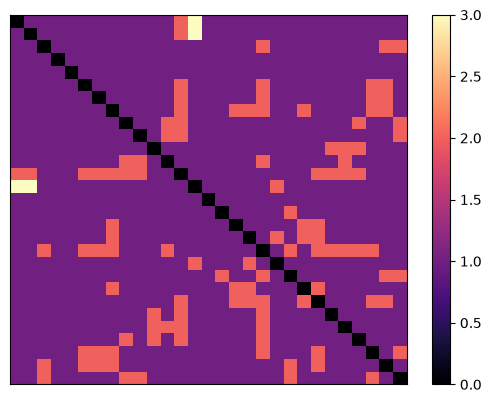

In [9]:
from ctreex.plot import metric_heat_map, leaf_metric_histogram
from ctreex.counterfactuals import volatility_index
matrix, leaf_ids, leaf_classes = explainer.leaf_distance_matrix()
metric_heat_map(matrix, leaf_ids, leaf_classes);

most volatile leaf: 29 (bad)


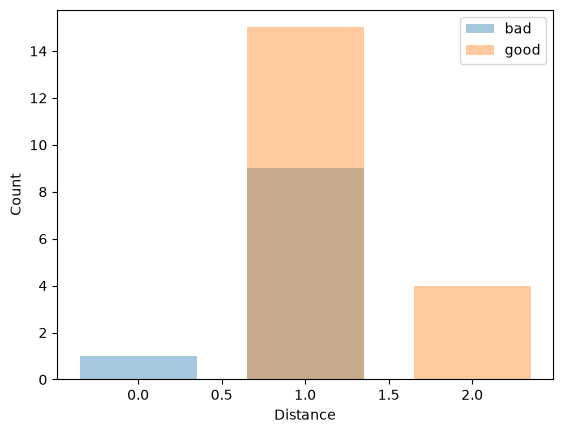

In [10]:
volatility = {leaf: volatility_index(leaf, matrix, leaf_ids, leaf_classes) for leaf in leaf_ids}
most_volatile = max(volatility, key=volatility.get)
print('most volatile leaf:', most_volatile, '({})'.format(leaf_classes[list(leaf_ids).index(most_volatile)]))
leaf_metric_histogram(most_volatile, matrix, leaf_ids, leaf_classes);